In [2]:
from sklearn.datasets import fetch_olivetti_faces

data = fetch_olivetti_faces()

X = data.data
y = data.target

print(X.shape)
print(y.shape)

downloading Olivetti faces from https://ndownloader.figshare.com/files/5976027 to /root/scikit_learn_data
(400, 4096)
(400,)


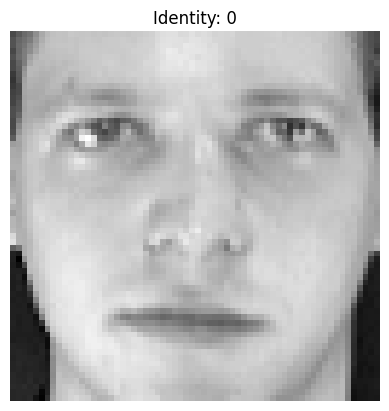

In [3]:
import matplotlib.pyplot as plt

i = 0  # image ka index

plt.imshow(X[i].reshape(64, 64), cmap="gray")
plt.title(f"Identity: {y[i]}")
plt.axis("off")
plt.show()

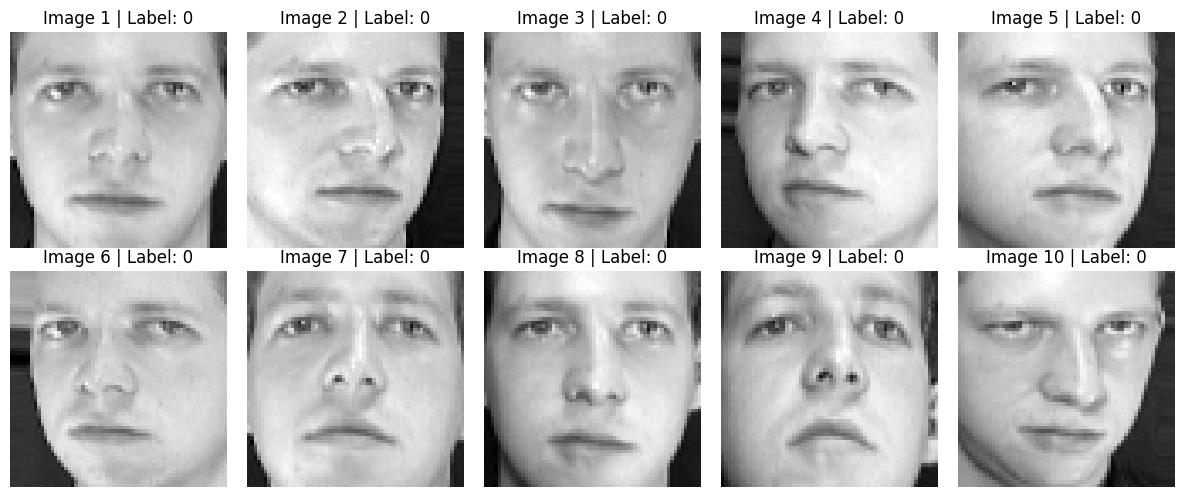

In [4]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    ax.imshow(X[i].reshape(64, 64), cmap="gray")
    ax.set_title(f"Image {i+1} | Label: {y[i]}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [5]:
## thee seed will assure thaat same data point is selcted in each split

In [6]:
import numpy as np

# Roll number m26cse008 -> seed 26008
rng = np.random.default_rng(26008)

# Har set ke image indices
train_indices = []
val_indices = []
test_indices = []

# Har identity ke liye 6:2:2 split
for person_id in range(40):


    indices = np.where(y == person_id)[0]


    indices = rng.permutation(indices)


    train_indices.extend(indices[:6])
    val_indices.extend(indices[6:8])
    test_indices.extend(indices[8:])


train_indices = np.array(train_indices)
val_indices = np.array(val_indices)
test_indices = np.array(test_indices)


X_train = X[train_indices]
y_train = y[train_indices]

X_val = X[val_indices]
y_val = y[val_indices]

X_test = X[test_indices]
y_test = y[test_indices]


print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)

Training: (240, 4096) (240,)
Validation: (80, 4096) (80,)
Testing: (80, 4096) (80,)


In [7]:
# i am saving the taki dobara code run hone pr whi images use ho

In [8]:
np.savez(
    "olivetti_split.npz",
    train_indices=train_indices,
    val_indices=val_indices,
    test_indices=test_indices
)

In [9]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

In [10]:
depths = [2, 4, 8, 16, None]
leaf_sizes = [1, 2, 4]

In [11]:
results = []

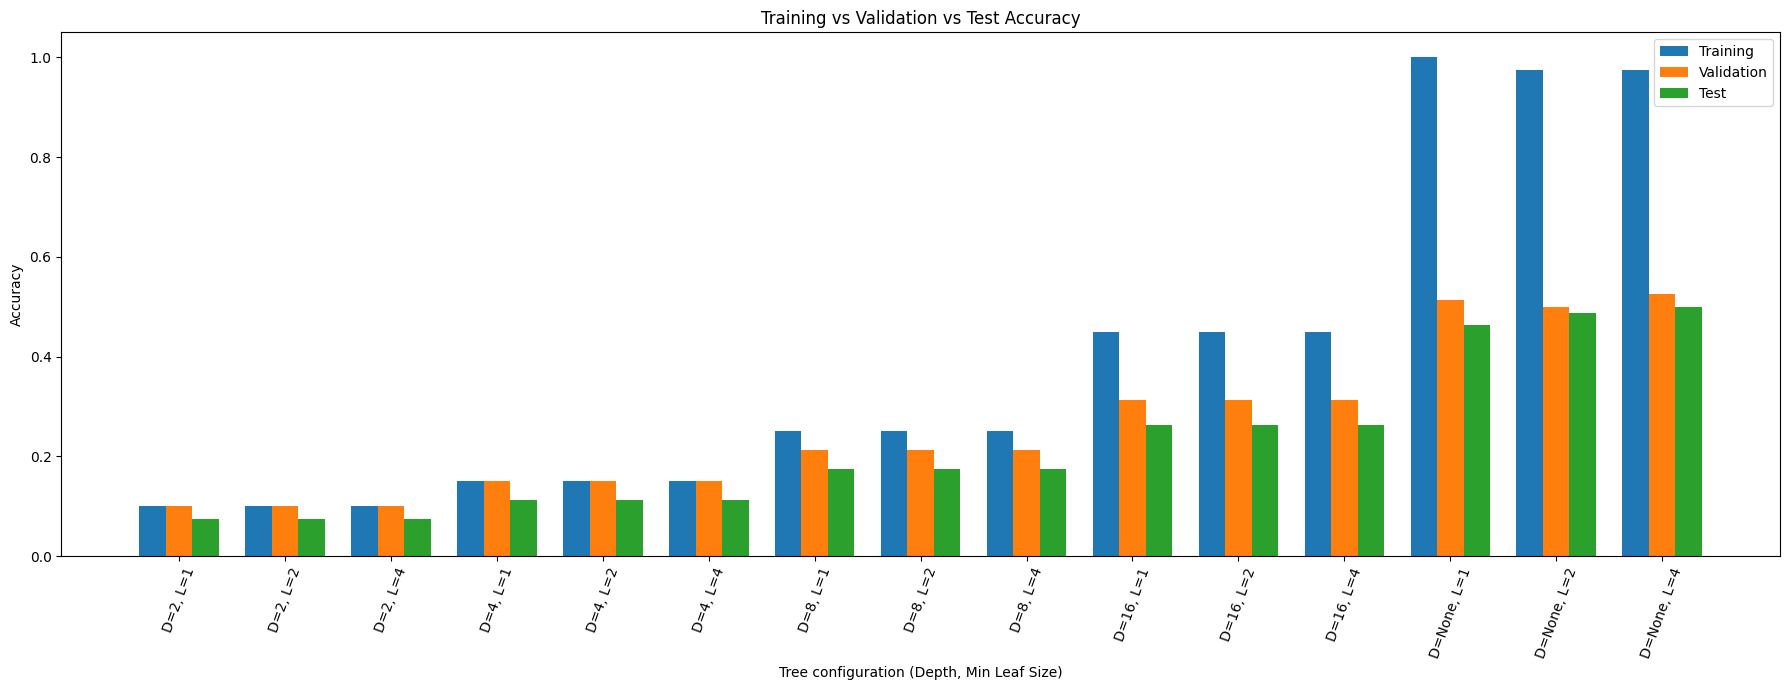

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

depths = [2, 4, 8, 16, None]
leaf_sizes = [1, 2, 4]

results = []

for depth in depths:
    for leaf_size in leaf_sizes:
        model = DecisionTreeClassifier(
            max_depth=depth,
            min_samples_leaf=leaf_size,
            random_state=26008
        )

        model.fit(X_train, y_train)

        train_acc = accuracy_score(
            y_train, model.predict(X_train)
        )

        val_acc = accuracy_score(
            y_val, model.predict(X_val)
        )

        test_acc = accuracy_score(
            y_test, model.predict(X_test)
        )

        results.append({
            "max_depth": depth,
            "min_samples_leaf": leaf_size,
            "train_accuracy": train_acc,
            "validation_accuracy": val_acc,
            "test_accuracy": test_acc
        })

labels = [
    f"D={r['max_depth']}, L={r['min_samples_leaf']}"
    for r in results
]

train_accs = [r["train_accuracy"] for r in results]
val_accs = [r["validation_accuracy"] for r in results]
test_accs = [r["test_accuracy"] for r in results]

x = np.arange(len(results))
width = 0.25

plt.figure(figsize=(18, 7))

plt.bar(x - width, train_accs, width, label="Training")
plt.bar(x, val_accs, width, label="Validation")
plt.bar(x + width, test_accs, width, label="Test")

plt.xticks(x, labels, rotation=70)
plt.ylim(0, 1.05)
plt.xlabel("Tree configuration (Depth, Min Leaf Size)")
plt.ylabel("Accuracy")
plt.title("Training vs Validation vs Test Accuracy")
plt.legend()
plt.tight_layout()
plt.show()

In [13]:
print(results)

[{'max_depth': 2, 'min_samples_leaf': 1, 'train_accuracy': 0.1, 'validation_accuracy': 0.1, 'test_accuracy': 0.075}, {'max_depth': 2, 'min_samples_leaf': 2, 'train_accuracy': 0.1, 'validation_accuracy': 0.1, 'test_accuracy': 0.075}, {'max_depth': 2, 'min_samples_leaf': 4, 'train_accuracy': 0.1, 'validation_accuracy': 0.1, 'test_accuracy': 0.075}, {'max_depth': 4, 'min_samples_leaf': 1, 'train_accuracy': 0.15, 'validation_accuracy': 0.15, 'test_accuracy': 0.1125}, {'max_depth': 4, 'min_samples_leaf': 2, 'train_accuracy': 0.15, 'validation_accuracy': 0.15, 'test_accuracy': 0.1125}, {'max_depth': 4, 'min_samples_leaf': 4, 'train_accuracy': 0.15, 'validation_accuracy': 0.15, 'test_accuracy': 0.1125}, {'max_depth': 8, 'min_samples_leaf': 1, 'train_accuracy': 0.25, 'validation_accuracy': 0.2125, 'test_accuracy': 0.175}, {'max_depth': 8, 'min_samples_leaf': 2, 'train_accuracy': 0.25, 'validation_accuracy': 0.2125, 'test_accuracy': 0.175}, {'max_depth': 8, 'min_samples_leaf': 4, 'train_accurac

In [14]:
best_result = max(
    results,
    key=lambda result: result["validation_accuracy"]
)

print("Best configuration:", best_result)

Best configuration: {'max_depth': None, 'min_samples_leaf': 4, 'train_accuracy': 0.975, 'validation_accuracy': 0.525, 'test_accuracy': 0.5}


In [15]:
# we have observed that depth = none and leaf =4 ke liye highest validation accuracy aa rhi h

In [16]:
best_depth = None
best_leaf_size = 4

In [17]:
best_model = DecisionTreeClassifier(
    max_depth=best_depth,
    min_samples_leaf=best_leaf_size,
    random_state=26008
)

best_model.fit(X_train, y_train)

y_val_pred = best_model.predict(X_val)

val_acc = accuracy_score(y_val, y_val_pred)
train_acc = accuracy_score(y_train, best_model.predict(X_train))
test_acc = accuracy_score(y_test, best_model.predict(X_test))

print("Train accuracy:", train_acc)
print("Validation accuracy:", val_acc)
print("Test accuracy:", test_acc)

Train accuracy: 0.975
Validation accuracy: 0.525
Test accuracy: 0.5


In [18]:
leaf_mask = (
    (best_model.tree_.children_left == -1) &
    (best_model.tree_.children_right == -1)
)

leaf_node_ids = np.where(leaf_mask)[0]

number_of_leaves = len(leaf_node_ids)

samples_per_leaf = best_model.tree_.n_node_samples[leaf_node_ids]

mean_samples_per_leaf = np.mean(samples_per_leaf)

fraction_single_sample_leaves = np.mean(samples_per_leaf == 1)

print("Number of leaves:", number_of_leaves)
print("Mean samples per leaf:", mean_samples_per_leaf)
print("Fraction of single-sample leaves:", fraction_single_sample_leaves)

Number of leaves: 40
Mean samples per leaf: 6.0
Fraction of single-sample leaves: 0.0


In [19]:
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

print("Frozen max_depth:", best_depth)
print("Frozen min_samples_leaf:", best_leaf_size)

X_train: (240, 4096)
y_train: (240,)
X_val: (80, 4096)
X_test: (80, 4096)
Frozen max_depth: None
Frozen min_samples_leaf: 4


In [20]:

def train_bagging(B, X_train, y_train,
                  best_depth, best_leaf_size, seed=26008):

    rng = np.random.default_rng(seed)
    n = len(X_train)

    trees = []
    distinct_counts = []

    for i in range(B):

        # Random bootstrap sample
        indices = rng.choice(n, size=n, replace=True)

        X_boot = X_train[indices]
        y_boot = y_train[indices]

        # Count unique training examples
        distinct_counts.append(len(np.unique(indices)))

        # Create and train decision tree
        tree = DecisionTreeClassifier(
            max_depth=best_depth,
            min_samples_leaf=best_leaf_size,
            random_state=seed + i
        )

        tree.fit(X_boot, y_boot)
        trees.append(tree)

    return trees, distinct_counts


In [21]:

import numpy as np
import pandas as pd
from sklearn.tree import DecisionTreeClassifier

B_values = [1, 5, 10, 25, 50, 100, 200]
seed = 26008
n = len(X_train)
rng = np.random.default_rng(seed)

all_trees = []
all_distinct_counts = []
all_bootstrap_indices = []

for i in range(max(B_values)):
    indices = rng.choice(n, size=n, replace=True)
    X_boot = X_train[indices]
    y_boot = y_train[indices]

    all_bootstrap_indices.append(indices.copy())
    all_distinct_counts.append(len(np.unique(indices)))

    tree = DecisionTreeClassifier(
        max_depth=best_depth,
        min_samples_leaf=best_leaf_size,
        random_state=seed + i
    )
    tree.fit(X_boot, y_boot)
    all_trees.append(tree)


def majority_vote(trees, X):
    predictions = np.array([tree.predict(X) for tree in trees])
    final_predictions = []

    for j in range(predictions.shape[1]):
        labels, counts = np.unique(predictions[:, j], return_counts=True)
        final_predictions.append(labels[np.argmax(counts)])

    return np.array(final_predictions)


results = []
stored_predictions = {}

for B in B_values:
    trees_B = all_trees[:B]

    train_pred = majority_vote(trees_B, X_train)
    val_pred = majority_vote(trees_B, X_val)
    test_pred = majority_vote(trees_B, X_test)

    stored_predictions[B] = {
        "train": train_pred,
        "validation": val_pred,
        "test": test_pred
    }

    results.append({
        "B": B,
        "train_accuracy": np.mean(train_pred == y_train),
        "validation_accuracy": np.mean(val_pred == y_val),
        "test_accuracy": np.mean(test_pred == y_test),
        "avg_distinct_examples": np.mean(all_distinct_counts[:B])
    })

results_df = pd.DataFrame(results)

N = len(X_train)
expected_distinct = N * (1 - (1 - 1/N)**N)

results_df["theoretical_expected_distinct"] = expected_distinct

print(results_df.round(4).to_string(index=False))
print("\nTheoretical expected distinct examples:", round(expected_distinct, 2))

results_df.to_csv("q1b_bagging_results.csv", index=False)

print("\nResults saved to q1b_bagging_results.csv")


  B  train_accuracy  validation_accuracy  test_accuracy  avg_distinct_examples  theoretical_expected_distinct
  1          0.6833               0.4500         0.4125                 158.00                       151.8932
  5          0.9208               0.6375         0.5500                 152.60                       151.8932
 10          0.9792               0.7125         0.7000                 152.10                       151.8932
 25          1.0000               0.7875         0.7750                 151.32                       151.8932
 50          1.0000               0.8250         0.8125                 151.70                       151.8932
100          1.0000               0.8625         0.8875                 152.44                       151.8932
200          1.0000               0.8750         0.8750                 151.93                       151.8932

Theoretical expected distinct examples: 151.89

Results saved to q1b_bagging_results.csv


In [22]:
## 1)c

In [23]:

import numpy as np
import pandas as pd

B_values = [1, 5, 10, 25, 50, 100, 200]
n = len(X_train)

train_tree_preds = np.array([
    tree.predict(X_train) for tree in all_trees
])

oob_matrix = np.array([
    ~np.isin(np.arange(n), indices)
    for indices in all_bootstrap_indices
])

metrics = []

for B in B_values:
    preds = train_tree_preds[:B]
    oob_flags = oob_matrix[:B]

    oob_predictions = np.full(n, -1, dtype=int)
    valid = oob_flags.sum(axis=0) > 0

    for j in np.where(valid)[0]:
        votes = preds[oob_flags[:, j], j]
        labels, counts = np.unique(votes, return_counts=True)
        oob_predictions[j] = labels[np.argmax(counts)]

    oob_accuracy = (
        np.mean(oob_predictions[valid] == y_train[valid])
        if np.any(valid) else np.nan
    )

    disagreements = []

    for i in range(B):
        for j in range(i + 1, B):
            disagreements.append(np.mean(preds[i] != preds[j]))

    avg_disagreement = (
        np.mean(disagreements) if disagreements else np.nan
    )

    margins = []

    for j in range(n):
        labels, counts = np.unique(preds[:, j], return_counts=True)
        counts = np.sort(counts)[::-1]

        winner_fraction = counts[0] / B
        runner_up_fraction = counts[1] / B if len(counts) > 1 else 0

        margins.append(winner_fraction - runner_up_fraction)

    mean_vote_margin = np.mean(margins)

    metrics.append({
        "B": B,
        "OOB_accuracy": oob_accuracy,
        "Pairwise_disagreement": avg_disagreement,
        "Mean_vote_margin": mean_vote_margin
    })

q1c_results_df = pd.DataFrame(metrics)

q1c_results_df = q1c_results_df.merge(
    results_df[["B", "validation_accuracy"]],
    on="B"
)

print(q1c_results_df.round(4).to_string(index=False))

q1c_results_df.to_csv("q1c_metrics.csv", index=False)
print("\nSaved: q1c_metrics.csv")

best_B = int(
    results_df.loc[
        results_df["validation_accuracy"].idxmax(), "B"
    ]
)

final_ensemble = all_trees[:best_B]

print("\nSelected ensemble size B =", best_B)


  B  OOB_accuracy  Pairwise_disagreement  Mean_vote_margin  validation_accuracy
  1        0.3049                    NaN            1.0000               0.4500
  5        0.3318                 0.5175            0.5192               0.6375
 10        0.3808                 0.5344            0.5500               0.7125
 25        0.5625                 0.5414            0.5762               0.7875
 50        0.6542                 0.5422            0.5923               0.8250
100        0.7292                 0.5422            0.5993               0.8625
200        0.7375                 0.5481            0.5971               0.8750

Saved: q1c_metrics.csv

Selected ensemble size B = 200


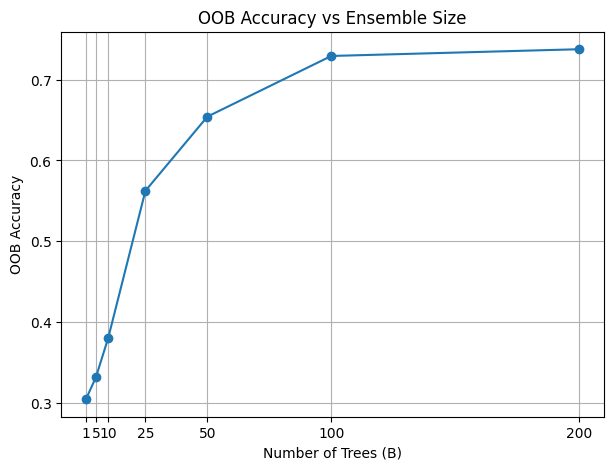

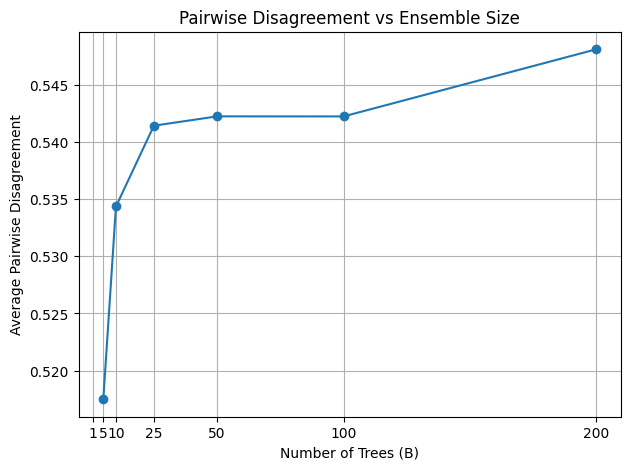

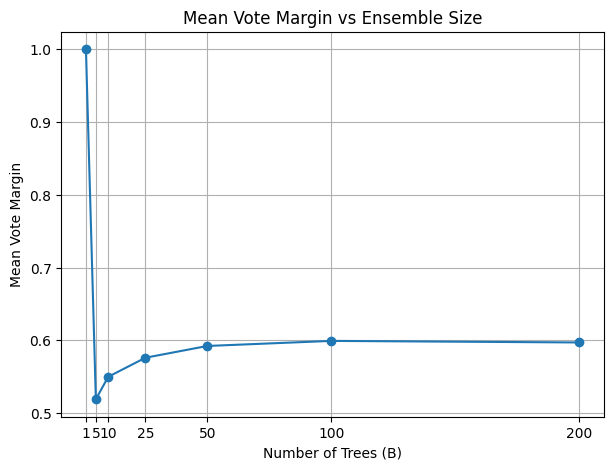

In [24]:

import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))
plt.plot(q1c_results_df["B"], q1c_results_df["OOB_accuracy"], marker="o")
plt.xlabel("Number of Trees (B)")
plt.ylabel("OOB Accuracy")
plt.title("OOB Accuracy vs Ensemble Size")
plt.xticks(B_values)
plt.grid(True)
plt.show()

plt.figure(figsize=(7, 5))
plt.plot(q1c_results_df["B"], q1c_results_df["Pairwise_disagreement"], marker="o")
plt.xlabel("Number of Trees (B)")
plt.ylabel("Average Pairwise Disagreement")
plt.title("Pairwise Disagreement vs Ensemble Size")
plt.xticks(B_values)
plt.grid(True)
plt.show()

plt.figure(figsize=(7, 5))
plt.plot(q1c_results_df["B"], q1c_results_df["Mean_vote_margin"], marker="o")
plt.xlabel("Number of Trees (B)")
plt.ylabel("Mean Vote Margin")
plt.title("Mean Vote Margin vs Ensemble Size")
plt.xticks(B_values)
plt.grid(True)
plt.show()


In [25]:

best_row = results_df.loc[results_df["validation_accuracy"].idxmax()]

best_B = int(best_row["B"])
best_val_accuracy = best_row["validation_accuracy"]

final_ensemble = all_trees[:best_B]

print("Selected ensemble size:", best_B)
print("Validation accuracy:", round(best_val_accuracy, 4))


Selected ensemble size: 200
Validation accuracy: 0.875


In [26]:
#1)d

In [27]:
tree_pred = best_model.predict(X_test)

bagging_preds = np.array([
    tree.predict(X_test) for tree in final_ensemble
])

bagging_pred = []
for j in range(len(y_test)):
    labels, counts = np.unique(
        bagging_preds[:, j], return_counts=True
    )
    bagging_pred.append(labels[np.argmax(counts)])

bagging_pred = np.array(bagging_pred)

In [28]:
tree_accuracy = np.mean(tree_pred == y_test)
tree_confidence = np.mean(
    best_model.predict_proba(X_test).max(axis=1)
)

bagging_accuracy = np.mean(bagging_pred == y_test)

bagging_confidence = np.mean(
    np.max(
        np.stack([
            np.mean(bagging_preds == cls, axis=0)
            for cls in np.unique(bagging_preds)
        ]),
        axis=0
    )
)

print("Clean Test Set")
print(f"Single Tree Accuracy: {tree_accuracy:.4f}")
print(f"Single Tree Mean Confidence: {tree_confidence:.4f}")
print(f"Bagging Accuracy: {bagging_accuracy:.4f}")
print(f"Bagging Mean Confidence: {bagging_confidence:.4f}")

Clean Test Set
Single Tree Accuracy: 0.5000
Single Tree Mean Confidence: 0.9765
Bagging Accuracy: 0.8750
Bagging Mean Confidence: 0.3644


In [29]:
corrected_faces = np.where(
    (tree_pred != y_test) &
    (bagging_pred == y_test)
)[0]

print("Corrected face indices:", corrected_faces[:2])
print("Total corrected faces:", len(corrected_faces))

Corrected face indices: [1 4]
Total corrected faces: 32


In [30]:
both_wrong_faces = np.where(
    (tree_pred != y_test) &
    (bagging_pred != y_test)
)[0]

print("Total faces where both are wrong:", len(both_wrong_faces))
print("First two face indices:", both_wrong_faces[:2])

Total faces where both are wrong: 8
First two face indices: [0 7]


In [31]:
for i in both_wrong_faces[:2]:
    labels, counts = np.unique(
        bagging_preds[:, i], return_counts=True
    )

    print("\nFace index:", i)
    print("Actual identity:", y_test[i])
    print("Tree prediction:", tree_pred[i])
    print("Bagging prediction:", bagging_pred[i])
    print("Bagging vote counts:", dict(zip(labels, counts)))


Face index: 0
Actual identity: 0
Tree prediction: 29
Bagging prediction: 25
Bagging vote counts: {np.int64(0): np.int64(11), np.int64(1): np.int64(11), np.int64(2): np.int64(7), np.int64(3): np.int64(5), np.int64(4): np.int64(9), np.int64(5): np.int64(7), np.int64(6): np.int64(2), np.int64(7): np.int64(10), np.int64(8): np.int64(9), np.int64(9): np.int64(1), np.int64(10): np.int64(7), np.int64(11): np.int64(1), np.int64(12): np.int64(2), np.int64(13): np.int64(3), np.int64(14): np.int64(6), np.int64(15): np.int64(8), np.int64(16): np.int64(5), np.int64(17): np.int64(11), np.int64(18): np.int64(1), np.int64(19): np.int64(4), np.int64(21): np.int64(6), np.int64(22): np.int64(1), np.int64(23): np.int64(2), np.int64(24): np.int64(1), np.int64(25): np.int64(19), np.int64(26): np.int64(3), np.int64(27): np.int64(10), np.int64(28): np.int64(6), np.int64(29): np.int64(3), np.int64(30): np.int64(7), np.int64(31): np.int64(4), np.int64(33): np.int64(2), np.int64(34): np.int64(2), np.int64(36): 

In [32]:
##doing same for masked test


In [33]:
X_test_masked = X_test.copy().reshape(-1, 64, 64)
X_test_masked[:, 24:40, 24:40] = 0
X_test_masked = X_test_masked.reshape(-1, 4096)

In [34]:
tree_pred_masked = best_model.predict(X_test_masked)

bagging_preds_masked = np.array([
    tree.predict(X_test_masked) for tree in final_ensemble
])

bagging_pred_masked = []

for j in range(len(y_test)):
    labels, counts = np.unique(
        bagging_preds_masked[:, j], return_counts=True
    )
    bagging_pred_masked.append(labels[np.argmax(counts)])

bagging_pred_masked = np.array(bagging_pred_masked)

In [35]:
tree_accuracy_masked = np.mean(tree_pred_masked == y_test)

tree_confidence_masked = np.mean(
    best_model.predict_proba(X_test_masked).max(axis=1)
)

bagging_accuracy_masked = np.mean(
    bagging_pred_masked == y_test
)

bagging_confidence_masked = np.mean(
    np.max(
        np.stack([
            np.mean(bagging_preds_masked == cls, axis=0)
            for cls in np.unique(bagging_preds_masked)
        ]),
        axis=0
    )
)

print("Masked Test Set")
print(f"Single Tree Accuracy: {tree_accuracy_masked:.4f}")
print(f"Single Tree Mean Confidence: {tree_confidence_masked:.4f}")
print(f"Bagging Accuracy: {bagging_accuracy_masked:.4f}")
print(f"Bagging Mean Confidence: {bagging_confidence_masked:.4f}")

Masked Test Set
Single Tree Accuracy: 0.5000
Single Tree Mean Confidence: 0.9765
Bagging Accuracy: 0.7875
Bagging Mean Confidence: 0.2567


In [36]:

corrected_faces_masked = np.where(
    (tree_pred_masked != y_test) &
    (bagging_pred_masked == y_test)
)[0]

print("Total corrected faces:", len(corrected_faces_masked))
print("First two face indices:", corrected_faces_masked[:2])

Total corrected faces: 27
First two face indices: [1 5]


In [37]:
for i in corrected_faces_masked[:2]:
    labels, counts = np.unique(
        bagging_preds_masked[:, i], return_counts=True
    )

    print("\nFace index:", i)
    print("Actual identity:", y_test[i])
    print("Tree prediction:", tree_pred_masked[i])
    print("Bagging prediction:", bagging_pred_masked[i])
    print("Bagging vote counts:", dict(zip(labels, counts)))


Face index: 1
Actual identity: 0
Tree prediction: 29
Bagging prediction: 0
Bagging vote counts: {np.int64(0): np.int64(39), np.int64(1): np.int64(21), np.int64(2): np.int64(1), np.int64(3): np.int64(10), np.int64(4): np.int64(7), np.int64(5): np.int64(8), np.int64(6): np.int64(1), np.int64(8): np.int64(4), np.int64(9): np.int64(7), np.int64(12): np.int64(9), np.int64(13): np.int64(13), np.int64(14): np.int64(4), np.int64(15): np.int64(8), np.int64(16): np.int64(3), np.int64(17): np.int64(6), np.int64(19): np.int64(4), np.int64(20): np.int64(3), np.int64(22): np.int64(2), np.int64(23): np.int64(1), np.int64(24): np.int64(1), np.int64(25): np.int64(2), np.int64(26): np.int64(1), np.int64(27): np.int64(3), np.int64(28): np.int64(2), np.int64(29): np.int64(1), np.int64(30): np.int64(8), np.int64(33): np.int64(12), np.int64(35): np.int64(10), np.int64(36): np.int64(1), np.int64(37): np.int64(7), np.int64(39): np.int64(1)}

Face index: 5
Actual identity: 2
Tree prediction: 4
Bagging predict

In [38]:
both_wrong_faces_masked = np.where(
    (tree_pred_masked != y_test) &
    (bagging_pred_masked != y_test)
)[0]

print("Total faces where both are wrong:", len(both_wrong_faces_masked))
print("First two face indices:", both_wrong_faces_masked[:2])

Total faces where both are wrong: 13
First two face indices: [0 4]


In [39]:
for i in both_wrong_faces_masked[:2]:
    labels, counts = np.unique(
        bagging_preds_masked[:, i], return_counts=True
    )

    print("\nFace index:", i)
    print("Actual identity:", y_test[i])
    print("Tree prediction:", tree_pred_masked[i])
    print("Bagging prediction:", bagging_pred_masked[i])
    print("Bagging vote counts:", dict(zip(labels, counts)))


Face index: 0
Actual identity: 0
Tree prediction: 29
Bagging prediction: 30
Bagging vote counts: {np.int64(0): np.int64(7), np.int64(1): np.int64(9), np.int64(2): np.int64(4), np.int64(3): np.int64(11), np.int64(4): np.int64(2), np.int64(5): np.int64(3), np.int64(6): np.int64(1), np.int64(7): np.int64(9), np.int64(8): np.int64(5), np.int64(9): np.int64(1), np.int64(10): np.int64(6), np.int64(12): np.int64(6), np.int64(13): np.int64(12), np.int64(14): np.int64(5), np.int64(15): np.int64(5), np.int64(16): np.int64(4), np.int64(17): np.int64(6), np.int64(19): np.int64(3), np.int64(20): np.int64(5), np.int64(21): np.int64(6), np.int64(23): np.int64(3), np.int64(24): np.int64(2), np.int64(25): np.int64(10), np.int64(26): np.int64(3), np.int64(27): np.int64(7), np.int64(28): np.int64(4), np.int64(29): np.int64(1), np.int64(30): np.int64(22), np.int64(31): np.int64(1), np.int64(32): np.int64(1), np.int64(33): np.int64(16), np.int64(34): np.int64(1), np.int64(35): np.int64(12), np.int64(36): 

In [40]:
import pandas as pd

results = {
    "Test Set": ["Clean", "Clean", "Masked", "Masked"],
    "Model": ["Single Tree", "Bagging", "Single Tree", "Bagging"],
    "Accuracy": [0.5000, 0.8750, 0.5000, 0.7875],
    "Mean Confidence": [0.9765, 0.3644, 0.9765, 0.2567]
}

df = pd.DataFrame(results)

df.to_csv("single_tree_vs_bagging.csv", index=False)

print(df)
print("\nCSV file saved successfully!")

  Test Set        Model  Accuracy  Mean Confidence
0    Clean  Single Tree    0.5000           0.9765
1    Clean      Bagging    0.8750           0.3644
2   Masked  Single Tree    0.5000           0.9765
3   Masked      Bagging    0.7875           0.2567

CSV file saved successfully!


In [41]:


for i in corrected_faces[:2]:
    labels, counts = np.unique(
        bagging_preds[:, i],
        return_counts=True
    )

    print(f"\nFace index: {i}")
    print(f"Actual class: {y_test[i]}")
    print(f"Single tree prediction: {tree_pred[i]}")
    print(f"Bagging prediction: {bagging_pred[i]}")
    print("Bagging vote counts:",
          dict(zip(labels, counts)))


Face index: 1
Actual class: 0
Single tree prediction: 29
Bagging prediction: 0
Bagging vote counts: {np.int64(0): np.int64(49), np.int64(1): np.int64(26), np.int64(2): np.int64(3), np.int64(3): np.int64(5), np.int64(4): np.int64(14), np.int64(5): np.int64(11), np.int64(6): np.int64(1), np.int64(7): np.int64(3), np.int64(8): np.int64(4), np.int64(9): np.int64(9), np.int64(10): np.int64(1), np.int64(12): np.int64(3), np.int64(13): np.int64(3), np.int64(15): np.int64(10), np.int64(16): np.int64(4), np.int64(17): np.int64(7), np.int64(18): np.int64(3), np.int64(19): np.int64(3), np.int64(22): np.int64(1), np.int64(24): np.int64(14), np.int64(25): np.int64(2), np.int64(27): np.int64(3), np.int64(28): np.int64(4), np.int64(29): np.int64(1), np.int64(36): np.int64(2), np.int64(37): np.int64(12), np.int64(39): np.int64(2)}

Face index: 4
Actual class: 2
Single tree prediction: 29
Bagging prediction: 2
Bagging vote counts: {np.int64(1): np.int64(5), np.int64(2): np.int64(34), np.int64(3): np.i